# Mean image from a selected frame interval

Choose the session, run, **starting frame (zero-based)** and number of frames below, then Run All. For example, `START_FRAME=100` and `N_FRAMES=50` averages frames **100–149**.

Reads the **registered Suite2p movie**, not the saved whole-recording mean image or fluorescence traces. The default is the functional stream (`data.bin`; green for these recordings). Select `CHANNEL='other'` for `data_chan2.bin`, or `'both'` to view both. All requested frames are included, including any frames flagged as bad by Suite2p. Only the requested interval is read, in small batches. No input files are modified.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

SUBJECT_DIR = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R')
SESSION = 218
RUN = 5
START_FRAME = int(500*7.5)      # Zero-based: 0 is the first frame.
N_FRAMES = 100        # Exactly this many consecutive frames.
CHANNEL = 'functional'  # 'functional', 'other', or 'both'
DISPLAY_PERCENTILES = (1, 99.8)  # Display contrast only; mean_image is unscaled.
BATCH_SIZE = 50

In [2]:
def mean_binary_interval(path, height, width, start, count, batch_size=50):
    """Mean of a contiguous interval in a Suite2p int16 registered binary."""
    for label, value, minimum in [('height',height,1),('width',width,1),
                                  ('start',start,0),('count',count,1),('batch_size',batch_size,1)]:
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < minimum:
            raise ValueError(f'{label} must be an integer >= {minimum}')
    frame_bytes = height * width * np.dtype(np.int16).itemsize
    size = path.stat().st_size
    if size == 0 or size % frame_bytes:
        raise ValueError(f'{path.name} does not contain complete int16 frames')
    total_frames = size // frame_bytes
    stop = start + count
    if stop > total_frames:
        raise ValueError(f'Requested frames {start}–{stop-1}, but {path.name} has '
                         f'{total_frames} frames (0–{total_frames-1}). Reduce START_FRAME or N_FRAMES.')
    total = np.zeros((height, width), dtype=np.float64)
    with path.open('rb') as handle:
        handle.seek(start * frame_bytes)
        for offset in range(0, count, batch_size):
            n = min(batch_size, count-offset)
            block = np.fromfile(handle, dtype=np.int16, count=n*height*width)
            if block.size != n*height*width:
                raise IOError(f'Unexpected end of {path}')
            total += block.reshape(n, height, width).sum(axis=0, dtype=np.float64)
    return total / count, total_frames

if CHANNEL not in ('functional','other','both'):
    raise ValueError("CHANNEL must be 'functional', 'other', or 'both'")
planes = sorted(SUBJECT_DIR.glob(f'ses-{SESSION}_*/funcimg/run-{RUN:02d}/suite2p/plane0'))
if len(planes) != 1:
    raise ValueError(f'Expected one plane0 folder for session {SESSION}, run {RUN}; found {planes}')
PLANE_DIR = planes[0]
ops = np.load(PLANE_DIR / 'ops.npy', allow_pickle=True).item()
height, width = int(ops['Ly']), int(ops['Lx'])
streams = {'functional': 'data.bin', 'other': 'data_chan2.bin'}
selected = list(streams) if CHANNEL == 'both' else [CHANNEL]
mean_images = {}
for stream in selected:
    binary = PLANE_DIR / streams[stream]
    mean_images[stream], total_frames = mean_binary_interval(
        binary, height, width, START_FRAME, N_FRAMES, BATCH_SIZE)
    print(f'{stream}: averaged {N_FRAMES} frames ({START_FRAME}–{START_FRAME+N_FRAMES-1}) '
          f'of {total_frames}; image {height} × {width}')
print('Source:', PLANE_DIR)
print('Physical functional-channel number in ops:', ops.get('functional_chan', 'unknown'))
# Convenient array when plotting only one channel; both remain in mean_images.
mean_image = mean_images[selected[0]]

functional: averaged 100 frames (3750–3849) of 9085; image 478 × 501
Source: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-218_date-20260801/funcimg/run-05/suite2p/plane0
Physical functional-channel number in ops: 2


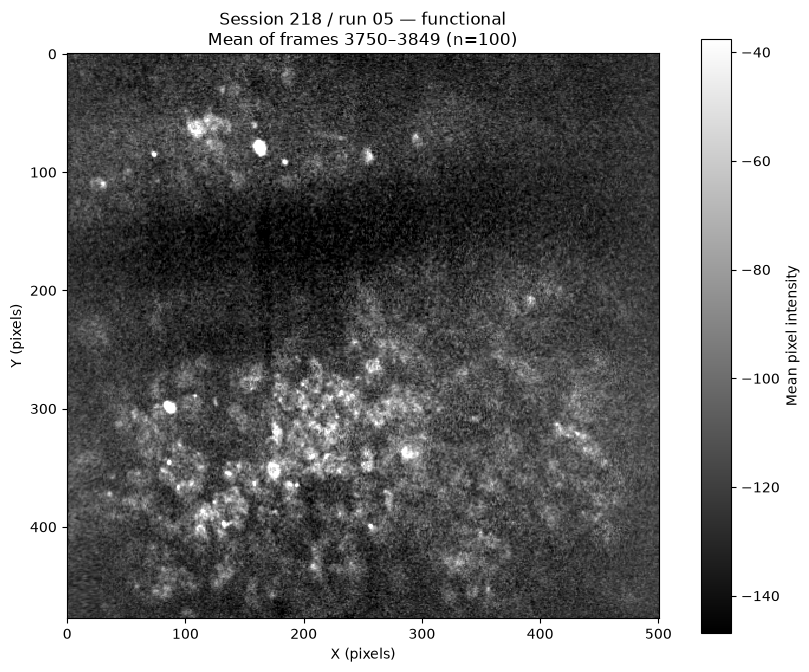

In [3]:
low, high = DISPLAY_PERCENTILES
if not 0 <= low < high <= 100:
    raise ValueError('Display percentiles must satisfy 0 <= low < high <= 100')
fig, axes = plt.subplots(1, len(mean_images), figsize=(8*len(mean_images), 8),
                         squeeze=False, constrained_layout=True)
for ax, (stream, image) in zip(axes.flat, mean_images.items()):
    vmin, vmax = np.percentile(image, DISPLAY_PERCENTILES)
    if vmax <= vmin:
        vmax = vmin + 1
    shown = ax.imshow(image, cmap='gray', vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.set_title(f'Session {SESSION} / run {RUN:02d} — {stream}\n'
                 f'Mean of frames {START_FRAME}–{START_FRAME+N_FRAMES-1} (n={N_FRAMES})')
    ax.set(xlabel='X (pixels)', ylabel='Y (pixels)')
    fig.colorbar(shown, ax=ax, label='Mean pixel intensity', shrink=.75)
plt.show()

## Mean image from a raw TIFF

This section can run independently of the registered-image cells. Paste the **full path to one raw TIFF** below. Reads one 2D image per TIFF page, with channels interleaved (for these recordings: red, green, red, green…). No registration, destriping, or distortion correction is applied.

`RAW_START_FRAME` is a **zero-based timepoint per channel**, not a TIFF page number. With two channels, timepoint 100 uses pages 200 (red) and 201 (green). `RAW_N_FRAMES=50` averages 50 images per selected channel. For a single-channel TIFF, set `RAW_N_CHANNELS=1` and `RAW_CHANNELS=[0]`. This section does not concatenate split TIFF files or interpret interleaved z-planes.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tifffile

RAW_TIFF_PATH = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-03_id-MY_71_R/ses-218_date-20260801/funcimg/71rtask_00015.tif')  # Replace with Path('/full/path/to/your_recording.tif')
RAW_START_FRAME = int(500*7.5) 
RAW_N_FRAMES = 1
RAW_N_CHANNELS = 2
RAW_CHANNELS = [1]  # [1]: green; [0]: red; [0, 1]: both (zero-based TIFF channel order).
RAW_DISPLAY_PERCENTILES = (1, 99.8)

In [2]:
def mean_raw_tiff_interval(path, start, count, n_channels, channels):
    """Average selected timepoints in a page-interleaved, single-plane TIFF."""
    for label, value, minimum in [('start',start,0), ('count',count,1), ('n_channels',n_channels,1)]:
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < minimum:
            raise ValueError(f'{label} must be an integer >= {minimum}')
    channels = list(channels)
    if not channels or any(isinstance(c, (bool, np.bool_)) or not isinstance(c, (int, np.integer))
                           or c < 0 or c >= n_channels for c in channels):
        raise ValueError('Select at least one valid zero-based channel index')
    if len(set(channels)) != len(channels):
        raise ValueError('Channel indices must be unique')
    with tifffile.TiffFile(path) as tif:
        n_pages = len(tif.pages)
        if n_pages == 0 or n_pages % n_channels:
            raise ValueError(f'{n_pages} TIFF pages cannot form complete {n_channels}-channel timepoints')
        n_timepoints = n_pages // n_channels
        if start + count > n_timepoints:
            raise ValueError(f'Requested timepoints {start}–{start+count-1}, but this TIFF has '
                             f'{n_timepoints} (0–{n_timepoints-1})')
        shape = tif.pages[0].shape
        if len(shape) != 2:
            raise ValueError(f'Expected one 2D image per page, found {shape}. Check TIFF layout.')
        sums = {channel: np.zeros(shape, dtype=np.float64) for channel in channels}
        for timepoint in range(start, start + count):
            for channel in channels:
                page = tif.pages[timepoint*n_channels + channel]
                if page.shape != shape:
                    raise ValueError('Image dimensions change within the selected interval')
                sums[channel] += page.asarray()
    return {channel: total/count for channel, total in sums.items()}, n_timepoints

# Reset these when rerunning so an unset path cannot leave a stale image displayed.
raw_mean_images = None
raw_mean_image = None
if RAW_TIFF_PATH is None:
    print('Set RAW_TIFF_PATH to the full path of your raw TIFF, then rerun this cell and the plot cell.')
else:
    raw_path = Path(RAW_TIFF_PATH).expanduser()
    if not raw_path.is_absolute() or not raw_path.is_file():
        raise FileNotFoundError(f'Provide an existing absolute TIFF path: {raw_path}')
    raw_mean_images, raw_total_frames = mean_raw_tiff_interval(
        raw_path, RAW_START_FRAME, RAW_N_FRAMES, RAW_N_CHANNELS, RAW_CHANNELS)
    raw_mean_image = next(iter(raw_mean_images.values()))  # Unscaled mean array.
    print('Source:', raw_path)
    print(f'Averaged {RAW_N_FRAMES} timepoints ({RAW_START_FRAME}–'
          f'{RAW_START_FRAME+RAW_N_FRAMES-1}) of {raw_total_frames}, per selected channel.')

Source: /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-03_id-MY_71_R/ses-218_date-20260801/funcimg/71rtask_00015.tif
Averaged 1 timepoints (3750–3750) of 9085, per selected channel.


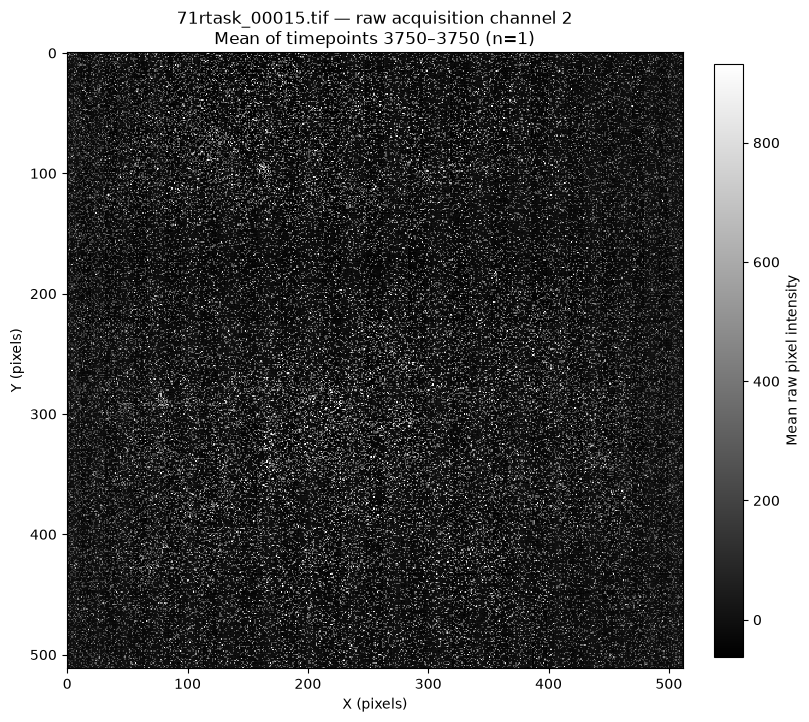

In [3]:
if raw_mean_images is None:
    print('Choose RAW_TIFF_PATH and run the raw mean calculation first.')
else:
    low, high = RAW_DISPLAY_PERCENTILES
    if not 0 <= low < high <= 100:
        raise ValueError('Display percentiles must satisfy 0 <= low < high <= 100')
    raw_fig, raw_axes = plt.subplots(1, len(raw_mean_images), figsize=(8*len(raw_mean_images), 8),
                                    squeeze=False, constrained_layout=True)
    for ax, (channel, image) in zip(raw_axes.flat, raw_mean_images.items()):
        vmin, vmax = np.percentile(image, RAW_DISPLAY_PERCENTILES)
        if vmax <= vmin:
            vmax = vmin + 1
        shown = ax.imshow(image, cmap='gray', vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.set_title(f'{raw_path.name} — raw acquisition channel {channel+1}\n'
                     f'Mean of timepoints {RAW_START_FRAME}–{RAW_START_FRAME+RAW_N_FRAMES-1} '
                     f'(n={RAW_N_FRAMES})')
        ax.set(xlabel='X (pixels)', ylabel='Y (pixels)')
        raw_fig.colorbar(shown, ax=ax, label='Mean raw pixel intensity', shrink=.75)
    plt.show()